In [1]:
# Q3 - STEP 1: IMPORT LIBRARIES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Settings
pd.set_option('display.max_columns', None)
plt.style.use('seaborn-v0_8')
sns.set(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Q3 - STEP 2: LOAD DATA & INSPECT
df = pd.read_csv('Mall_Customers.csv')

print("=== SHAPE ===")
print("Rows, Columns:", df.shape)
print("\n=== COLUMN NAMES ===")
print(df.columns.tolist())

print("\n=== FIRST 5 ROWS ===")
df.head()

=== SHAPE ===
Rows, Columns: (200, 5)

=== COLUMN NAMES ===
['CustomerID', 'Genre', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

=== FIRST 5 ROWS ===


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
# Q3 - STEP 2b: INSPECT - Age, Annual Income, Spending Score
print("=== DATA TYPES & MISSING VALUES ===")
print(df.info())
print("\nMissing values:\n", df.isnull().sum())

print("\n=== SUMMARY FOR KEY FEATURES ===")
df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']].describe()

print("\n=== UNIQUE VALUES CHECK ===")
print("Gender values:", df['Gender'].unique())

=== DATA TYPES & MISSING VALUES ===
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Genre                   200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB
None

Missing values:
 CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

=== SUMMARY FOR KEY FEATURES ===

=== UNIQUE VALUES CHECK ===


KeyError: 'Gender'

In [4]:
# Q3 - STEP 2b FIXED
print("=== MISSING VALUES ===")
print(df.isnull().sum())

print("\n=== SUMMARY FOR KEY FEATURES ===")
df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']].describe()

print("\n=== GENRE COUNTS ===")
print(df['Genre'].value_counts())

=== MISSING VALUES ===
CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

=== SUMMARY FOR KEY FEATURES ===

=== GENRE COUNTS ===
Genre
Female    112
Male       88
Name: count, dtype: int64


In [5]:
# Q3 - STEP 2c: SUMMARY TABLE
print(df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']].describe())

              Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000          200.000000              200.000000
mean    38.850000           60.560000               50.200000
std     13.969007           26.264721               25.823522
min     18.000000           15.000000                1.000000
25%     28.750000           41.500000               34.750000
50%     36.000000           61.500000               50.000000
75%     49.000000           78.000000               73.000000
max     70.000000          137.000000               99.000000


In [6]:
# Q3 - STEP 3: DATA WRANGLING + SCALING

# 1. Drop ID - it is not useful for clustering
# 2. Keep only numerical features for clustering
X = df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']]

print("Features used for clustering:")
print(X.head())
print("\nShape of X:", X.shape)

# 3. Scale with StandardScaler
# Why? Age is 18-70, Income is 15-137, Spending is 1-100
# KMeans uses distance, so we must put them on same scale
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\n=== AFTER SCALING ===")
print("First 5 scaled rows:")
print(X_scaled[:5])

# Convert back to DataFrame so it's easy to read
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)
print("\n=== CHECK SCALING WORKED ===")
print("Mean should be ~0:")
print(X_scaled_df.mean())
print("\nStd should be ~1:")
print(X_scaled_df.std())

Features used for clustering:
   Age  Annual Income (k$)  Spending Score (1-100)
0   19                  15                      39
1   21                  15                      81
2   20                  16                       6
3   23                  16                      77
4   31                  17                      40

Shape of X: (200, 3)

=== AFTER SCALING ===
First 5 scaled rows:
[[-1.42456879 -1.73899919 -0.43480148]
 [-1.28103541 -1.73899919  1.19570407]
 [-1.3528021  -1.70082976 -1.71591298]
 [-1.13750203 -1.70082976  1.04041783]
 [-0.56336851 -1.66266033 -0.39597992]]

=== CHECK SCALING WORKED ===
Mean should be ~0:
Age                      -1.021405e-16
Annual Income (k$)       -2.131628e-16
Spending Score (1-100)   -1.465494e-16
dtype: float64

Std should be ~1:
Age                       1.002509
Annual Income (k$)        1.002509
Spending Score (1-100)    1.002509
dtype: float64


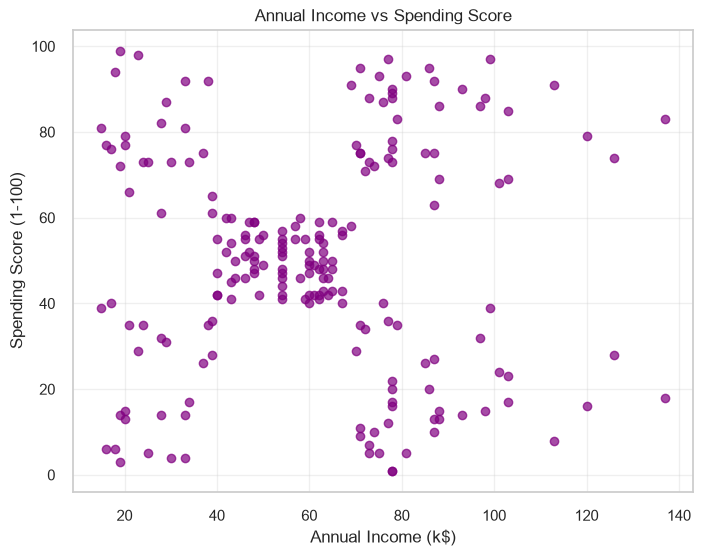

In [7]:
# Q3 - STEP 4: EDA - SCATTER PLOTS

# 1. BASIC - Income vs Spending (Can you see 5 groups?)
plt.figure(figsize=(8, 6))
plt.scatter(df['Annual Income (k$)'], df['Spending Score (1-100)'], alpha=0.7, color='purple')
plt.title('Annual Income vs Spending Score')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.grid(True, alpha=0.3)
plt.show()

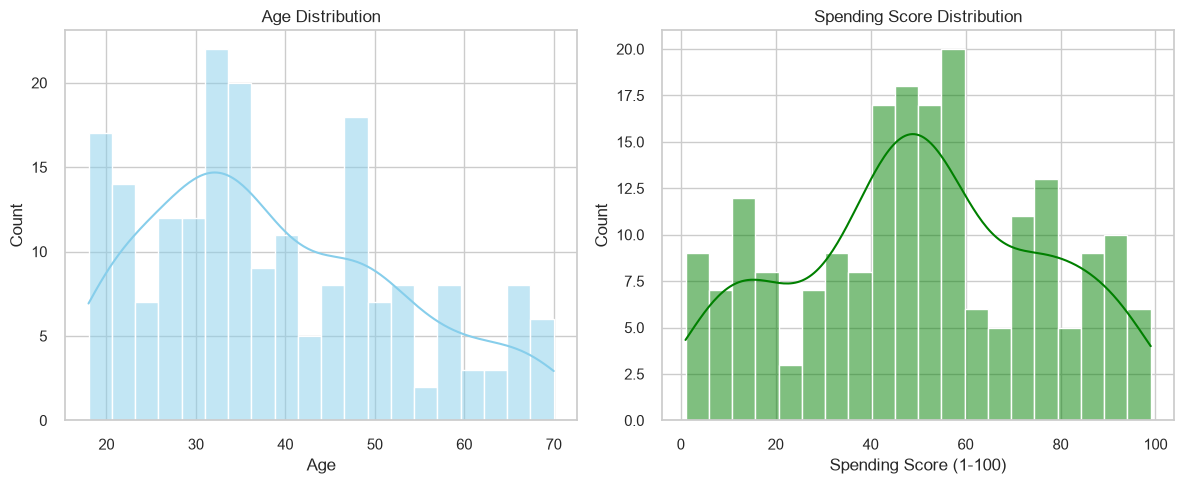

In [8]:
# Q3 - STEP 4b: DISTRIBUTION PLOTS - Age & Spending Score

plt.figure(figsize=(12, 5))

# 1. AGE DISTRIBUTION
plt.subplot(1, 2, 1)
sns.histplot(df['Age'], kde=True, color='skyblue', bins=20)
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Count')

# 2. SPENDING SCORE DISTRIBUTION
plt.subplot(1, 2, 2)
sns.histplot(df['Spending Score (1-100)'], kde=True, color='green', bins=20)
plt.title('Spending Score Distribution')
plt.xlabel('Spending Score (1-100)')
plt.ylabel('Count')

plt.tight_layout()
plt.show()

C:\Users\zach\Pictures\Camera Roll\New folder\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\zach\Pictures\Camera Roll\New folder\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\zach\Pictures\Camera Roll\New folder\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\zach\Pictures\Camera Roll\New folder\Lib\site-packages\sklearn\c

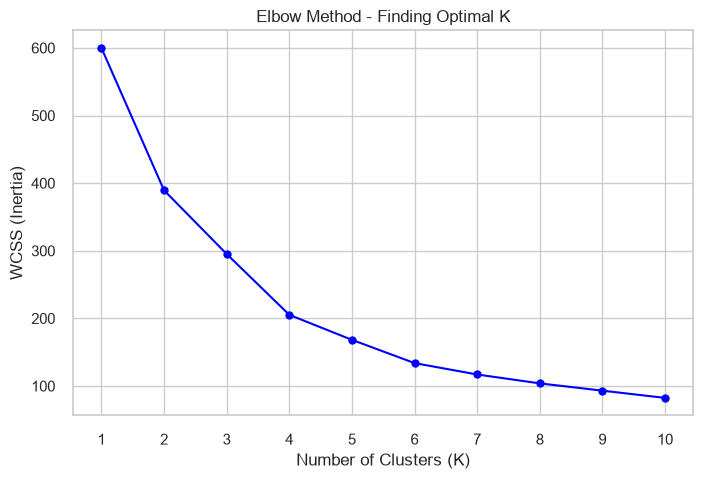

WCSS values:
K=1: 600.00
K=2: 389.39
K=3: 295.21
K=4: 205.23
K=5: 168.25
K=6: 133.87
K=7: 117.01
K=8: 103.87
K=9: 93.09
K=10: 82.39


In [9]:
# Q3 - STEP 5: ELBOW METHOD - Find Best K
wcss = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K_range, wcss, marker='o', color='blue')
plt.title('Elbow Method - Finding Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS (Inertia)')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

print("WCSS values:")
for k, w in zip(K_range, wcss):
    print(f"K={k}: {w:.2f}")

In [10]:
# Q3 - STEP 5: MODEL BUILDING - KMEANS CLUSTERING
import warnings
warnings.filterwarnings('ignore')

# 1. Build the model with K=5 (from Elbow Method)
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)

# 2. Fit on scaled data and get cluster labels
df['Cluster'] = kmeans.fit_predict(X_scaled)

print("MODEL BUILT SUCCESSFULLY!")
print("\nCustomers in each Cluster:")
print(df['Cluster'].value_counts().sort_index())

print("\n=== CLUSTER CENTERS (Original Scale) ===")
# Convert centers back to real Age, Income, Spending values
centers = scaler.inverse_transform(kmeans.cluster_centers_)
centers_df = pd.DataFrame(centers, columns=['Age', 'Annual Income (k$)', 'Spending Score (1-100)'])
print(centers_df.round(1))

print("\n=== MEAN VALUES PER CLUSTER ===")
print(df.groupby('Cluster')[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']].mean().round(1))

MODEL BUILT SUCCESSFULLY!

Customers in each Cluster:
Cluster
0    20
1    54
2    40
3    39
4    47
Name: count, dtype: int64

=== CLUSTER CENTERS (Original Scale) ===
    Age  Annual Income (k$)  Spending Score (1-100)
0  46.2                26.8                    18.3
1  25.2                41.1                    62.2
2  32.9                86.1                    81.5
3  39.9                86.1                    19.4
4  55.6                54.4                    48.9

=== MEAN VALUES PER CLUSTER ===
          Age  Annual Income (k$)  Spending Score (1-100)
Cluster                                                  
0        46.2                26.8                    18.4
1        25.2                41.1                    62.2
2        32.9                86.1                    81.5
3        39.9                86.1                    19.4
4        55.6                54.4                    48.9


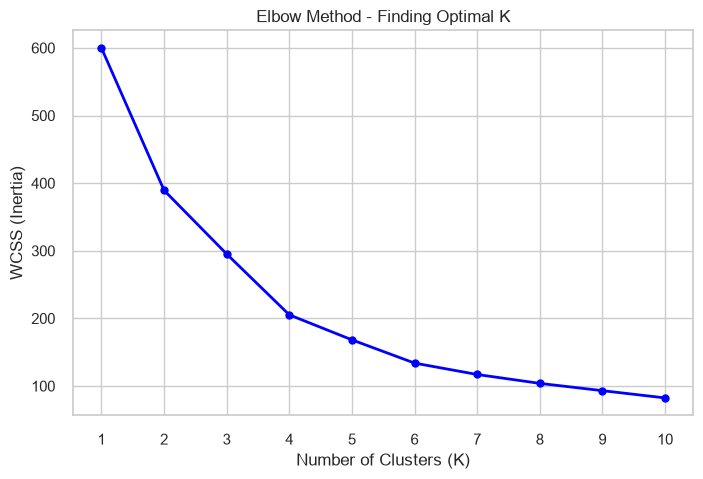

WCSS values:
K=1: 600.00
K=2: 389.39
K=3: 295.21
K=4: 205.23
K=5: 168.25
K=6: 133.87
K=7: 117.01
K=8: 103.87
K=9: 93.09
K=10: 82.39


In [11]:
# Q3 - STEP 5b: ELBOW METHOD - Find Optimal K
import warnings
warnings.filterwarnings('ignore')

wcss = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K_range, wcss, marker='o', color='blue', linewidth=2)
plt.title('Elbow Method - Finding Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS (Inertia)')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

print("WCSS values:")
for k, w in zip(K_range, wcss):
    print(f"K={k}: {w:.2f}")

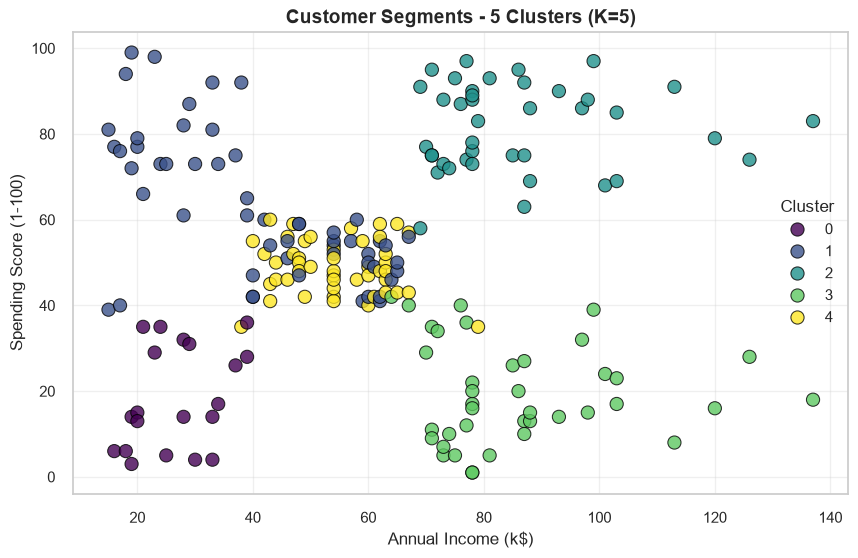

In [12]:
# Q3 - STEP 6a: PLOT CLUSTERS WITH DIFFERENT COLOURS
import warnings
warnings.filterwarnings('ignore')

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='Annual Income (k$)', y='Spending Score (1-100)', 
                hue='Cluster', palette='viridis', s=90, edgecolor='black', alpha=0.8)
plt.title('Customer Segments - 5 Clusters (K=5)', fontsize=14, fontweight='bold')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Cluster', loc='best')
plt.grid(True, alpha=0.3)
plt.show()

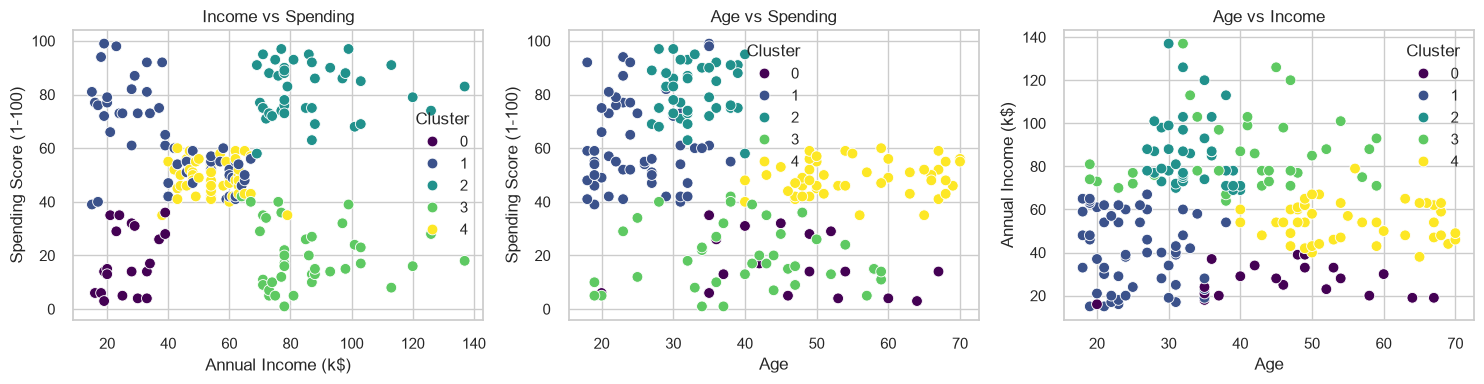

In [13]:
# Q3 - STEP 6a (Part 2): ALL 3 FEATURES
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.scatterplot(data=df, x='Annual Income (k$)', y='Spending Score (1-100)', hue='Cluster', palette='viridis', s=60, ax=axes[0])
axes[0].set_title('Income vs Spending')

sns.scatterplot(data=df, x='Age', y='Spending Score (1-100)', hue='Cluster', palette='viridis', s=60, ax=axes[1])
axes[1].set_title('Age vs Spending')

sns.scatterplot(data=df, x='Age', y='Annual Income (k$)', hue='Cluster', palette='viridis', s=60, ax=axes[2])
axes[2].set_title('Age vs Income')

plt.tight_layout()
plt.show()

In [14]:
# Q3 - STEP 6b: INTERPRETATION TABLE
summary = df.groupby('Cluster')[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']].mean().round(1)
summary['Count'] = df['Cluster'].value_counts().sort_index()
print(summary)

          Age  Annual Income (k$)  Spending Score (1-100)  Count
Cluster                                                         
0        46.2                26.8                    18.4     20
1        25.2                41.1                    62.2     54
2        32.9                86.1                    81.5     40
3        39.9                86.1                    19.4     39
4        55.6                54.4                    48.9     47



### Step 6b: Interpretation - Final Customer Segments

**Cluster 0 (20 customers):** Older customers (46.2 years) with low income (26.8k) and low spending (18.4). Budget / Cautious customers.

**Cluster 1 (54 customers - BIGGEST GROUP):** Young customers (25.2 years) with medium income (41.1k) but high spending (62.2). Young Impulsive Spenders.

**Cluster 2 (40 customers):** Young adults (32.9 years) with high income (86.1k) and high spending (81.5). Premium / Target Customers.

**Cluster 3 (39 customers):** Middle-aged (39.9 years) with high income (86.1k) but very low spending (19.4). Careful Rich customers.

**Cluster 4 (47 customers):** Oldest group (55.6 years) with middle income (54.4k) and middle spending (48.9). Average / Moderate customers.

**Conclusion:** K-Means successfully segmented 200 customers into 5 groups. The mall should focus on Premium Customers and convert Careful Rich customers with targeted offers.
